# Встреча 6. Решение, мемо, портфель: практика

> **Время:** 55 минут · **Опирается на:** `theory.ipynb` · **Данные:** `../data/checkout_ab.csv`, `../data/hotdeals_segmented.csv`, `../data/portfolio_tests.csv` · **Артефакт:** `memo_template.md`

**Легенда.** Тест нового чекаута отработал запланированные две недели. Владелец продукта ждёт мемо: внедряем или нет, сколько это денег и чем мы рискуем. Параллельно продакт «Горящих предложений» прислал разрезы по сегментам («смотрите, у low и mid значимо!»), а на квартальном ревью-борде надо объединить шесть тестов портфеля.

| № | Задание | Минут |
| :---: | --- | :---: |
| 1 | Эффект чекаута с ДИ — в метрике и в деньгах, сравнение с порогом | 12 |
| 2 | Guardrail как non-inferiority и решение по 4 метрикам с ролями | 10 |
| 3 | Сегменты: сколько «значимых» без поправки и с ней, A/A-проверка | 12 |
| 4 | Портфель: fixed/random effects, I², forest plot, две доли выигрышей | 13 |
| 5 | Мемо на страницу | 8 |

Формат: задание → ячейка `# ВАШ КОД` → свёрнутое решение → ячейка «Проверка» с `assert`.

* **Свой код проверяйте так:** запустите свою ячейку, затем сразу «Проверку», пропустив ячейку решения.
* **Решение перезаписывает ваши переменные и функции.** Поэтому не нажимайте Run All, если проверяете своё: он выполнит решения поверх вашего кода. На незаполненной заглушке Run All остановится с `NotImplementedError`.
* **Застряли больше 5 минут** — запустите решение: дальше ноутбук опирается на его переменные.

## 0. Подготовка

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2, norm
from statsmodels.stats.multitest import multipletests

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY, ORANGE = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F', '#DD8452'

from IPython.display import Markdown, display

DATA = Path('../data')


def spaced(value: float) -> str:
    """Форматирует число с пробелами между разрядами."""
    return f'{value:,.0f}'.replace(',', ' ')

### Вход: вердикт встречи 1 и бизнес-параметры

Правило решения зафиксировано до запуска: одностороннее $\alpha = 0.5$ против точки безубыточности, то есть **внедряем, если наблюдаемая разница конверсий выше 0.246 п.п.** Деньги считаем по модели встречи 1: выручка 137 млн ₽ в неделю, затраты на тест, внедрение и год поддержки — 25 млн ₽, горизонт — 52 недели.

Граница non-inferiority для ошибок оплаты тоже записана заранее: рост не больше **+0.2 п.п.** (10% от базовых 2%).

In [2]:
VERDICT = {'alpha': 0.5, 'break_even_pp': 0.246, 'n_b': 21000, 'n_total': 105000, 'days': 14, 'decision': 'тестируем'}

WEEKLY_REVENUE = 137_000_000              # ₽ в неделю (встреча 1)
WEEKLY_USERS = 7_500 * 7                  # пользователей чекаута в неделю
COSTS = {'тест': 3_000_000, 'внедрение': 10_000_000, 'поддержка за год': 12 * 1_000_000}
TOTAL_COSTS = sum(COSTS.values())         # 25 млн ₽
HORIZON_WEEKS = 52
BE_PP = VERDICT['break_even_pp']          # порог решения, п.п.
NI_MARGIN_PP = 0.20                       # guardrail: ошибки оплаты растут не больше чем на 0.2 п.п.
print(f"Затраты: {TOTAL_COSTS / 1e6:.0f} млн ₽; порог решения: {BE_PP} п.п.; граница non-inferiority: +{NI_MARGIN_PP} п.п.")

Затраты: 25 млн ₽; порог решения: 0.246 п.п.; граница non-inferiority: +0.2 п.п.


### Данные чекаута

Повторяем очистку **как на встрече 3**: убираем полные дубли строк и целиком — пользователей, попавших в обе группы. Затем SRM: план — 80/20.

In [3]:
def clean_checkout(raw: pd.DataFrame) -> pd.DataFrame:
    """Очистка как на встрече 3: полные дубли строк, затем целиком — пользователи в обеих группах."""
    dedup = raw.drop_duplicates()
    n_groups = dedup.groupby('user_id')['group'].nunique()
    return dedup[~dedup['user_id'].isin(n_groups[n_groups > 1].index)].reset_index(drop=True)


raw = pd.read_csv(DATA / 'checkout_ab.csv')
df = clean_checkout(raw)
assert df['user_id'].is_unique

counts = df['group'].value_counts().reindex(['A', 'B'])
srm_p = chi2.sf(((counts - len(df) * np.array([0.8, 0.2])) ** 2 / (len(df) * np.array([0.8, 0.2]))).sum(), 1)
print(f"Строк: {spaced(len(raw))} → {spaced(len(df))}; A = {spaced(counts['A'])}, B = {spaced(counts['B'])}; SRM p = {srm_p:.3f}")
assert (counts['A'], counts['B'], len(df)) == (83_878, 21_082, 104_960) and abs(srm_p - 0.487) < 0.001, 'Очистка должна совпасть со встречей 3'
A, B = df[df['group'] == 'A'], df[df['group'] == 'B']

Строк: 105 330 → 104 960; A = 83 878, B = 21 082; SRM p = 0.487


### Лестница решения

| Шаг | Вопрос | Где считаем |
| --- | --- | --- |
| 1. Данные | Можно ли верить сравнению? (SRM, очистка) | Подготовка |
| 2. Эффект | Насколько изменился OEC, 95% ДИ? | Задание 1 |
| 3. Деньги | Сколько это за горизонт, с ДИ? | Задание 1 |
| 4. Порог | Оценка выше BE (правило встречи 1)? | Задание 1 |
| 5. Guardrail | Доказано ли, что вред меньше границы? | Задание 2 |
| 6. Решение | внедряем / не внедряем как есть / не внедряем | Задание 2 → мемо |

Шаги 4 и 5 — оба необходимые условия. Провал любого из них останавливает внедрение, но по-разному. Провал шага 4 — «не внедряем». Провал шага 5 при пройденном шаге 4 — «не внедряем как есть».

## Задание 1. Эффект в метрике и в деньгах (12 минут)

1. Напишите `diff_ci(x_a, x_b, level=0.95)` — разница средних $\bar x_B - \bar x_A$, её SE (непулированная дисперсия) и двусторонний ДИ. Вернуть словарь `{'effect', 'se', 'ci'}`.
2. Посчитайте эффект на конверсию в п.п.: `effect_pp` и `ci_pp` (кортеж из двух чисел).
3. Переведите в деньги за горизонт. Относительный эффект $\theta = \delta / \hat p_A$ даёт ту же долю выручки:

$$
\text{money}(\delta) = \frac{\delta}{\hat p_A}\cdot 137\ \text{млн ₽} \cdot 52 - 25\ \text{млн ₽}.
$$

   Напишите `to_money(delta_pp)` (п.п. → чистые ₽) и сохраните `money_net` и `money_ci` (кортеж ₽).
4. Для сверки — те же деньги через ARPU: $\Delta\text{ARPU}\cdot 52\,500 \cdot 52 - 25$ млн ₽. Сохраните `arpu_money_ci` (кортеж ₽).

In [4]:
# ВАШ КОД
raise NotImplementedError

NotImplementedError: 

In [5]:
# @title Решение (нажмите, чтобы раскрыть)
def diff_ci(x_a, x_b, level=0.95):
    x_a, x_b = np.asarray(x_a, float), np.asarray(x_b, float)
    effect = x_b.mean() - x_a.mean()
    se = np.sqrt(x_a.var(ddof=1) / x_a.size + x_b.var(ddof=1) / x_b.size)
    z = norm.ppf(0.5 + level / 2)
    return {'effect': effect, 'se': se, 'ci': (effect - z * se, effect + z * se)}


p_a = A['converted'].mean()
conv = diff_ci(A['converted'], B['converted'])
effect_pp = 100 * conv['effect']
ci_pp = tuple(100 * np.array(conv['ci']))


def to_money(delta_pp):
    return np.asarray(delta_pp) / (100 * p_a) * WEEKLY_REVENUE * HORIZON_WEEKS - TOTAL_COSTS


money_net = float(to_money(effect_pp))
money_ci = tuple(float(v) for v in to_money(ci_pp))

arpu = diff_ci(A['revenue'], B['revenue'])
arpu_money_ci = tuple(float(v) * WEEKLY_USERS * HORIZON_WEEKS - TOTAL_COSTS for v in arpu['ci'])
arpu_money = float(arpu['effect']) * WEEKLY_USERS * HORIZON_WEEKS - TOTAL_COSTS

print(f"Конверсия: A = {p_a:.2%}, B = {B['converted'].mean():.2%}; эффект {effect_pp:+.2f} п.п. "
      f"[{ci_pp[0]:+.2f}; {ci_pp[1]:+.2f}], относительный {effect_pp / (100 * p_a):+.2%}")
print(f"В деньгах за год (чистыми): {money_net / 1e6:+.1f} млн ₽ [{money_ci[0] / 1e6:+.1f}; {money_ci[1] / 1e6:+.1f}]")
print(f"Через ARPU: Δ = {arpu['effect']:+.1f} ₽ [{arpu['ci'][0]:+.1f}; {arpu['ci'][1]:+.1f}] → "
      f"{arpu_money / 1e6:+.1f} млн ₽ [{arpu_money_ci[0] / 1e6:+.1f}; {arpu_money_ci[1] / 1e6:+.1f}]")

Конверсия: A = 69.87%, B = 71.26%; эффект +1.40 п.п. [+0.71; +2.08], относительный +2.00%
В деньгах за год (чистыми): +117.5 млн ₽ [+47.6; +187.4]
Через ARPU: Δ = +38.0 ₽ [-11.7; +87.6] → +78.6 млн ₽ [-56.8; +214.1]


**Проверка.** Эффект и ДИ сверяем с `statsmodels`; деньги — с порогом: при эффекте ровно BE чистые деньги близки к нулю.

In [6]:
# Проверка
from statsmodels.stats.proportion import confint_proportions_2indep

lo, hi = confint_proportions_2indep(B['converted'].sum(), len(B), A['converted'].sum(), len(A), method='wald', compare='diff')
assert np.allclose(np.array(ci_pp) / 100, (lo, hi), atol=1e-6), 'ДИ разницы конверсий не совпадает со statsmodels (Wald)'
assert abs(effect_pp - 1.398) < 0.001 and abs(ci_pp[0] - 0.712) < 0.001 and abs(ci_pp[1] - 2.083) < 0.001
assert abs(float(to_money(BE_PP))) < 0.5e6, 'При эффекте, равном BE, чистые деньги должны быть ≈ 0'
assert abs(money_net / 1e6 - 117.5) < 0.2 and abs(money_ci[0] / 1e6 - 47.6) < 0.2 and abs(money_ci[1] / 1e6 - 187.4) < 0.2
assert arpu_money_ci[0] < 0 < arpu_money_ci[1], 'ДИ денег через ARPU должен накрывать ноль'
print('Задание 1 принято')

Задание 1 принято


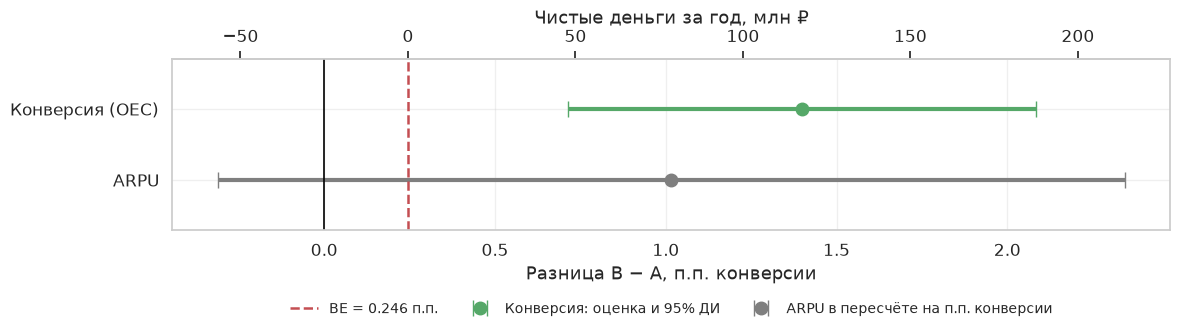

In [7]:
fig, ax = plt.subplots(figsize=(12, 4.0))
ax.errorbar(effect_pp, 1, xerr=[[effect_pp - ci_pp[0]], [ci_pp[1] - effect_pp]], fmt='o', color=GREEN, capsize=6, lw=3, ms=9,
            label='Конверсия: оценка и 95% ДИ')
arpu_pp = [(m + TOTAL_COSTS) / (WEEKLY_REVENUE * HORIZON_WEEKS) * 100 * p_a for m in arpu_money_ci]
ax.errorbar(np.mean(arpu_pp), 0, xerr=np.diff(arpu_pp) / 2, fmt='o', color=GRAY, capsize=6, lw=3, ms=9,
            label='ARPU в пересчёте на п.п. конверсии')
ax.axvline(0, color='black', lw=1.2)
ax.axvline(BE_PP, color=RED, ls='--', lw=1.8, label=f'BE = {BE_PP} п.п.')
ax.set_yticks([1, 0], ['Конверсия (OEC)', 'ARPU'])
ax.set_ylim(-0.7, 1.7)
ax.set_xlabel('Разница B − A, п.п. конверсии')
top = ax.secondary_xaxis('top', functions=(lambda d: to_money(d) / 1e6,
                                           lambda m: (np.asarray(m) * 1e6 + TOTAL_COSTS) / (WEEKLY_REVENUE * HORIZON_WEEKS) * 100 * p_a))
top.set_xlabel('Чистые деньги за год, млн ₽')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.35), ncol=3, frameon=False, fontsize=10)
plt.tight_layout()
plt.show()

**Вопрос.** Что сказать владельцу продукта: «эффект значим» или «выше порога»? И почему деньги считаем через конверсию, хотя у нас есть выручка?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

**«Выше порога»:**

* нижняя граница +0.71 п.п. почти втрое выше BE 0.25 п.п.;
* в деньгах +118 млн ₽ за год, ДИ от +48 до +187: окупается даже при худшем правдоподобном эффекте;
* p < 0.001 против нуля для решения ничего не добавляет.

**Почему через конверсию:**

* Деньги через конверсию — модель с допущением: **средний чек не меняется**, выручка растёт пропорционально конверсии. Так считали точку безубыточности на встрече 1.
* В данных чек в B на 0.5% ниже, незначимо (теория, блок 2; доп. задание Д2). Поэтому модель через конверсию немного оптимистична.
* Через ARPU точечная оценка ≈ +79 млн ₽ против +118 млн ₽ через конверсию. ДИ ARPU — примерно от −57 до +214 млн ₽, он накрывает ноль: выручка шумная, с тяжёлым хвостом.
* В мемо: оценка через конверсию, допущение — явно, ARPU-сверка — в «Рисках».

</details>

## Задание 2. Guardrail и решение по ролям метрик (10 минут)

Роли и правило записаны до запуска (как в дизайн-доке встречи 2):

| Метрика | Колонка | Роль | Проверка |
| --- | --- | --- | --- |
| Конверсия в заказ | `converted` | **OEC** | оценка выше BE = 0.246 п.п. ($\alpha = 0.5$ против BE) |
| ARPU | `revenue` | вторичная | двусторонняя, поправка Холма внутри семейства вторичных |
| Время на чекауте | `checkout_time_sec` | вторичная | двусторонняя, поправка Холма внутри семейства вторичных |
| Ошибки оплаты | `payment_error` | **guardrail** | non-inferiority: $H_0: \delta \ge +0.2$ п.п., одностороннее $\alpha = 0.05$, без поправки |

**Правило:** внедряем, если данные надёжны (SRM в норме), OEC выше порога **и** guardrail доказал non-inferiority. Если OEC выше порога, а guardrail не прошёл — «не внедряем как есть». Это **правило эскалации из дизайн-дока встречи 2**. Решает верхняя граница ДИ, а не точечная оценка. Внедрение приостановлено, причину ухудшения разбираем, после исправления — подтверждающий тест на мощность guardrail 0.9. Иначе — «не внедряем».

1. Напишите `non_inferiority(x_a, x_b, margin_pp, alpha=0.05)` для метрики, где рост — плохо. Вернуть `{'effect_pp', 'upper_pp', 'p_value', 'passed'}`: `upper_pp` — односторонняя верхняя граница $(1-\alpha)$, `p_value` — для $H_0: \delta \ge$ margin, `passed` — `upper_pp < margin_pp`.
2. Соберите таблицу `results` по четырём метрикам (индекс — колонка) со столбцами `role`, `effect`, `ci_low`, `ci_high`, `p_value`, `p_adj`. Для вторичных `p_adj` — по Холму, для остальных равен `p_value`. Для OEC и guardrail `p_value` — по их правилам: для OEC — $H_0: \delta \le$ BE, для guardrail — из `non_inferiority`.
3. Сохраните `guardrail = non_inferiority(...)` и `DECISION` — одну из строк `'внедряем'`, `'не внедряем как есть'`, `'не внедряем'`.

In [8]:
# ВАШ КОД
raise NotImplementedError

NotImplementedError: 

In [9]:
# @title Решение (нажмите, чтобы раскрыть)
def non_inferiority(x_a, x_b, margin_pp, alpha=0.05):
    r = diff_ci(x_a, x_b)
    effect_pp, se_pp = 100 * r['effect'], 100 * r['se']
    upper_pp = effect_pp + norm.ppf(1 - alpha) * se_pp
    p_value = norm.cdf((effect_pp - margin_pp) / se_pp)     # малое p — доказали «рост меньше границы»
    return {'effect_pp': effect_pp, 'upper_pp': upper_pp, 'p_value': p_value, 'passed': upper_pp < margin_pp}


ROLES = {'converted': 'OEC', 'revenue': 'вторичная', 'checkout_time_sec': 'вторичная', 'payment_error': 'guardrail'}
rows = []
for col, role in ROLES.items():
    r = diff_ci(A[col], B[col])
    if role == 'OEC':
        p = norm.sf((100 * r['effect'] - BE_PP) / (100 * r['se']))
    elif role == 'guardrail':
        p = non_inferiority(A[col], B[col], NI_MARGIN_PP)['p_value']
    else:
        p = 2 * norm.sf(abs(r['effect'] / r['se']))
    rows.append({'metric': col, 'role': role, 'A': A[col].mean(), 'B': B[col].mean(), 'effect': r['effect'],
                 'ci_low': r['ci'][0], 'ci_high': r['ci'][1], 'p_value': p})
results = pd.DataFrame(rows).set_index('metric')
results['p_adj'] = results['p_value']
secondary = results['role'] == 'вторичная'
results.loc[secondary, 'p_adj'] = multipletests(results.loc[secondary, 'p_value'], method='holm')[1]

guardrail = non_inferiority(A['payment_error'], B['payment_error'], NI_MARGIN_PP)
oec_passed = effect_pp > BE_PP
if srm_p > 0.001 and oec_passed and guardrail['passed']:
    DECISION = 'внедряем'
elif oec_passed:
    DECISION = 'не внедряем как есть'
else:
    DECISION = 'не внедряем'

print(f"Guardrail: рост ошибок {guardrail['effect_pp']:+.3f} п.п. (≈ {guardrail['effect_pp']:+.2f}), верхняя граница {guardrail['upper_pp']:+.2f} п.п. "
      f"при границе +{NI_MARGIN_PP} → {'прошёл' if guardrail['passed'] else 'НЕ прошёл'} (p = {guardrail['p_value']:.2f})")
print('Решение:', DECISION)
results.round(4)

Guardrail: рост ошибок +0.198 п.п. (≈ +0.20), верхняя граница +0.38 п.п. при границе +0.2 → НЕ прошёл (p = 0.49)
Решение: не внедряем как есть


,role,A,B,effect,ci_low,ci_high,p_value,p_adj
metric,,,,,,,,
converted,OEC,0.6987,0.7126,0.0140,0.0071,0.0208,0.0005,0.0005
revenue,вторичная,2604.4189,2642.3745,37.9556,-11.6615,87.5727,0.1338,0.1338
checkout_time_sec,вторичная,113.5294,110.3546,-3.1747,-4.2790,-2.0705,0.0000,0.0000
payment_error,guardrail,0.0200,0.0220,0.0020,-0.0002,0.0042,0.4930,0.4930


**Проверка.**

In [10]:
# Проверка
assert list(results.index) == ['converted', 'revenue', 'checkout_time_sec', 'payment_error']
assert abs(guardrail['effect_pp'] - 0.198) < 0.001 and abs(guardrail['upper_pp'] - 0.382) < 0.001
assert not guardrail['passed'] and abs(guardrail['p_value'] - 0.49) < 0.01, 'p-value non-inferiority — для H0: δ ≥ margin'
assert results.loc['converted', 'p_value'] < 0.001, 'OEC: H0 — разница не выше BE'
assert abs(results.loc['revenue', 'p_adj'] - 0.134) < 0.001 and results.loc['checkout_time_sec', 'p_adj'] < 1e-6
assert results.loc['payment_error', 'p_adj'] == results.loc['payment_error', 'p_value'], 'Guardrail без поправки'
assert DECISION == 'не внедряем как есть'
print('Задание 2 принято')

Задание 2 принято


**Анти-пример.** Тот же guardrail, проверенный «как обычно» — двусторонним тестом против нуля:

In [11]:
r = diff_ci(A['payment_error'], B['payment_error'])
p_two = 2 * norm.sf(abs(r['effect'] / r['se']))
print(f"Двусторонний тест против нуля: p = {p_two:.3f} → «незначимо, вреда нет».")
print(f"Non-inferiority: верхняя граница +{guardrail['upper_pp']:.2f} п.п. > +{NI_MARGIN_PP} → безопасность не доказана.")

Двусторонний тест против нуля: p = 0.077 → «незначимо, вреда нет».
Non-inferiority: верхняя граница +0.38 п.п. > +0.2 → безопасность не доказана.


**Вопрос.** Почему «незначимо» по guardrail ещё не значит «безопасно»? Что делать дальше и сколько стоит ожидание?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Незначимость — это отсутствие доказательств вреда, а не доказательство его отсутствия. Двусторонний тест против нуля даёт p = 0.077 и «зелёный свет», хотя оценка роста ошибок +0.198 п.п. (≈ +0.20, +10%) почти на самой границе допустимого. Верхняя граница — +0.38 п.п., почти вдвое выше неё. Non-inferiority ставит бремя доказательства на новый вариант: он должен показать, что вред меньше границы. Здесь не показал.

Решение — **не внедряем как есть**. Конверсия растёт с запасом, поэтому вариант не выбрасываем:

1. Ищем причину ошибок оплаты: способ оплаты, платформа, банк. Это задача разработки, не статистики.
2. После исправления — подтверждающий тест по **правилу эскалации из дизайн-дока встречи 2**. Мощность закладываем **на guardrail**, как в плане встречи 2: $1 - \beta/(G+1) = 0.9$. Показать non-inferiority с границей 0.2 п.п. при истинной разнице 0: нужно $SE \le 0.2 / (1.645 + 1.28) = 0.068$ п.п. При сплите 50/50 это ≈ 84 тыс. пользователей на группу (≈ 168 тыс. всего), 23 дня трафика, в целых неделях — **4 недели** (расчёт — ячейка ниже). На мощности 0.8 хватило бы 17 дней. Но тогда guardrail снова стал бы самым слабым звеном решения, а план встречи 2 именно это и запретил. Сплит 50/50, а не 80/20, как на встрече 1: для non-inferiority нужна минимальная SE, а сбалансированный сплит её даёт. Риск для B ниже — баг починен. Правило решения записываем до старта: внедряем, если верхняя граница ошибок оплаты < +0.2 п.п. и конверсия выше BE. BE пересчитываем (ячейка ниже): затраты первого теста (3 млн ₽) — невозвратные, стоимость фикса (допущение: 1 млн ₽) добавляется. Порог ≈ 0.23 п.п. вместо 0.246.
3. Цена ожидания: каждая неделя без нового чекаута — это $\theta \cdot 137 \approx 2.7$ млн ₽ недополученной выручки при $\theta = 2\%$. Чинить быстро выгоднее, чем спорить о правиле.

Менять правило задним числом («конверсия же выросла») нельзя — это подгонка под результат.

</details>

In [12]:
FIX_COST = 1_000_000   # допущение: стоимость исправления оплаты; 3 млн ₽ первого теста — невозвратные
be_confirm_pp = (TOTAL_COSTS - COSTS['тест'] + FIX_COST) / (WEEKLY_REVENUE * HORIZON_WEEKS) * 100 * p_a
print(f"BE подтверждающего теста: {be_confirm_pp:.3f} п.п. (было {BE_PP})")

# Подтверждающий тест: non-inferiority по ошибкам оплаты, мощность guardrail из плана встречи 2
CONFIRM_POWER, CONFIRM_SHARE_B = 0.9, 0.5
p_err_a = A['payment_error'].mean()
z_ni = norm.ppf(0.95) + norm.ppf(CONFIRM_POWER)
confirm_n = int(np.ceil(z_ni ** 2 * p_err_a * (1 - p_err_a) * (1 / CONFIRM_SHARE_B + 1 / (1 - CONFIRM_SHARE_B))
                        / (NI_MARGIN_PP / 100) ** 2))
confirm_days = int(np.ceil(confirm_n / (WEEKLY_USERS / 7)))
confirm_weeks = int(np.ceil(confirm_days / 7))
print(f"Подтверждающий тест 50/50, мощность {CONFIRM_POWER}: N = {spaced(confirm_n)} "
      f"({spaced(confirm_n / 2)} на группу), {confirm_days} дн. трафика → {confirm_weeks} нед.")
assert confirm_days == 23 and confirm_weeks == 4

BE подтверждающего теста: 0.226 п.п. (было 0.246)
Подтверждающий тест 50/50, мощность 0.9: N = 167 699 (83 850 на группу), 23 дн. трафика → 4 нед.


### Связь со встречей 1

Встреча 1 спрашивала: стоит ли тестировать, если можно просто раскатить? Модель сказала «тестируем»: ожидаемая прибыль 26.0 млн ₽ против 2.75 млн ₽ при раскатке без теста. Теперь видно, откуда эта ценность.

* Без теста мы раскатили бы рост конверсии **вместе с ростом ошибок оплаты**, которого в конверсии не видно.
* Правило встречи 1 сработало: по OEC вариант выше порога, причём нижняя граница ДИ тоже выше BE, так что вывод по OEC не зависит от выбора α. Поэтому вариант не выбрасываем.
* Guardrail из плана встречи 2 сработал тоже. Верхняя граница роста ошибок оплаты +0.38 п.п. выше допуска +0.2, и по правилу эскалации из дизайн-дока встречи 2 это «не внедряем как есть», хотя точечная оценка (+0.198) формально ниже допуска. Внедрение приостановлено, причину разбираем, после исправления — подтверждающий тест на мощность guardrail 0.9. «Не внедряем как есть» не отменяет правило встречи 1, а добавляет к нему второе необходимое условие.

Тест окупился не раскаткой, а тем, что нашёл, что чинить.

## Задание 3. Сегменты без p-hacking (12 минут)

Кейс «Горящие предложения» (встреча 4): 28 дней, сплит 50/50, метрика — `booked`. Продакт прислал разрезы. По условию кейса **преднамеченными** были два разреза: `device` и `is_new` — гипотеза, что блок сильнее помогает мобильным и новичкам. Остальное — разведка: `segment` (активность), `tenure` (корзины стажа) и пересечение `device × is_new`.

Колонки `tenure` (корзины стажа), `device_new` и функция `slice_effects(data, col)` даны в ячейке ниже: прочитайте, что такое `diff_ci` и `p_het`. Функция возвращает по значениям `col`: `n`, `effect_pp` и `se_pp` (эффект в сегменте), `p` (против нуля), `diff_pp` и `p_het` (разница эффекта «сегмент − остальные» и её двусторонний p — тест взаимодействия).

1. Соберите `slices` по `SLICE_COLS` (15 строк) — это 15 строк, но не 15 независимых гипотез: у бинарного разреза обе строки дают один и тот же `p_het`, а `tenure 0–30` совпадает с `is_new = new`. Поправка по 15 строкам — консервативная. Посчитайте, сколько сегментов «значимы» при 5%: `n_sig_raw`, `n_sig_holm`, `n_sig_bh` (по `p`, поправки — по всем 15) и `n_het_raw`, `n_het_holm` (по `p_het`).
2. A/A-проверка: 300 раз перемешайте метки групп (`rng = np.random.default_rng(6)`, `rng.permutation`) и посчитайте, сколько из 15 сегментов «выстрелит» по `p` при 5%. Сохраните массив `aa_counts`.

In [13]:
hd = pd.read_csv(DATA / 'hotdeals_segmented.csv')
SLICE_COLS = ['device', 'is_new', 'segment', 'tenure', 'device_new']
PREREGISTERED = ['device', 'is_new']
hd.head()

,user_id,date,group,booked,revenue,cancelled,device,reg_date,tenure_days,is_new,orders_90d,segment
0,100000,2026-09-07,B,0,0,0,mobile,2026-03-08,183,0,2,mid
1,100001,2026-09-07,A,0,0,0,mobile,2026-08-27,11,1,1,low
2,100002,2026-09-07,B,0,0,0,web,2026-05-30,100,0,4,mid
3,100003,2026-09-07,A,0,0,0,mobile,2025-06-24,440,0,5,high
4,100004,2026-09-07,A,0,0,0,mobile,2025-09-08,364,0,4,mid


#### Готовая функция: эффект в сегменте и тест взаимодействия

In [14]:
hd['is_new'] = np.where(hd['is_new'] == 1, 'new', 'old')
hd['tenure'] = pd.cut(hd['tenure_days'], [-1, 30, 180, 365, 730], labels=['0–30', '31–180', '181–365', '366–730']).astype(str)
hd['device_new'] = hd['device'] + '/' + hd['is_new']


def slice_effects(data, col):
    rows = []
    for value in sorted(data[col].unique()):
        inside = data[col] == value
        seg = data[inside]
        rest = data[~inside]
        e_in = diff_ci(seg.loc[seg['group'] == 'A', 'booked'], seg.loc[seg['group'] == 'B', 'booked'])
        e_out = diff_ci(rest.loc[rest['group'] == 'A', 'booked'], rest.loc[rest['group'] == 'B', 'booked'])
        diff, se_diff = e_in['effect'] - e_out['effect'], np.hypot(e_in['se'], e_out['se'])
        rows.append({'slice': col, 'value': value, 'n': int(inside.sum()),
                     'effect_pp': 100 * e_in['effect'], 'se_pp': 100 * e_in['se'],
                     'p': 2 * norm.sf(abs(e_in['effect'] / e_in['se'])),
                     'diff_pp': 100 * diff, 'p_het': 2 * norm.sf(abs(diff / se_diff))})
    return pd.DataFrame(rows)

In [15]:
# ВАШ КОД
raise NotImplementedError

NotImplementedError: 

In [16]:
# @title Решение (нажмите, чтобы раскрыть)
slices = pd.concat([slice_effects(hd, col) for col in SLICE_COLS], ignore_index=True)
for column in ['p', 'p_het']:
    slices[column + '_holm'] = multipletests(slices[column], method='holm')[1]
    slices[column + '_bh'] = multipletests(slices[column], method='fdr_bh')[1]
n_sig_raw, n_sig_holm, n_sig_bh = [(slices[c] < 0.05).sum() for c in ['p', 'p_holm', 'p_bh']]
n_het_raw, n_het_holm = [(slices[c] < 0.05).sum() for c in ['p_het', 'p_het_holm']]

# A/A: перемешиваем метки групп — эффекта нет ни в одном сегменте
rng = np.random.default_rng(6)
masks = np.array([(hd[col] == value).to_numpy() for col, value in zip(slices['slice'], slices['value'])], dtype=float)
y = hd['booked'].to_numpy(float)
is_b = (hd['group'] == 'B').to_numpy(float)
aa_counts = []
for _ in range(300):
    b = rng.permutation(is_b)
    n_b, n_all = masks @ b, masks.sum(axis=1)
    s_b, s_all = masks @ (y * b), masks @ y
    p_b, p_a_ = s_b / n_b, (s_all - s_b) / (n_all - n_b)
    se = np.sqrt(p_b * (1 - p_b) / n_b + p_a_ * (1 - p_a_) / (n_all - n_b))
    aa_counts.append(int((2 * norm.sf(np.abs(p_b - p_a_) / se) < 0.05).sum()))
aa_counts = np.array(aa_counts)

total = diff_ci(hd.loc[hd['group'] == 'A', 'booked'], hd.loc[hd['group'] == 'B', 'booked'])
print(f"Общий эффект: {100 * total['effect']:+.2f} п.п. (p = {2 * norm.sf(total['effect'] / total['se']):.1e})")
print(f"Значимы против нуля: без поправки {n_sig_raw} из 15, Холм {n_sig_holm}, BH {n_sig_bh}")
print(f"Отличаются от остальных (взаимодействие): без поправки {n_het_raw}, Холм {n_het_holm}")
print(f"A/A: в среднем выстреливает {aa_counts.mean():.2f} сегмента, хотя бы один — в {np.mean(aa_counts >= 1):.0%} прогонов")
slices.round(3)

Общий эффект: +0.35 п.п. (p = 1.0e-03)
Значимы против нуля: без поправки 8 из 15, Холм 2, BH 5
Отличаются от остальных (взаимодействие): без поправки 2, Холм 1
A/A: в среднем выстреливает 0.68 сегмента, хотя бы один — в 35% прогонов


,slice,value,n,effect_pp,se_pp,p,diff_pp,p_het,p_holm,p_bh,p_het_holm,p_het_bh
0,device,mobile,92423,0.525,0.140,0.000,0.389,0.070,0.003,0.001,0.909,0.262
1,device,web,75735,0.136,0.163,0.403,-0.389,0.070,1.000,0.504,0.909,0.262
2,is_new,new,50759,0.563,0.197,0.004,0.306,0.190,0.055,0.016,1.000,0.356
3,is_new,old,117399,0.257,0.126,0.042,-0.306,0.190,0.382,0.080,1.000,0.356
4,segment,high,26158,0.145,0.264,0.583,-0.243,0.399,1.000,0.672,1.000,0.599
5,segment,low,61254,0.400,0.177,0.024,0.079,0.721,0.240,0.060,1.000,0.772
6,segment,mid,80746,0.379,0.154,0.014,0.056,0.791,0.152,0.042,1.000,0.791
7,tenure,0–30,50759,0.563,0.197,0.004,0.306,0.190,0.055,0.016,1.000,0.356
8,tenure,181–365,30899,0.494,0.244,0.043,0.177,0.513,0.382,0.080,1.000,0.700
9,tenure,31–180,25341,0.451,0.271,0.096,0.120,0.683,0.577,0.144,1.000,0.772


**Проверка.**

In [17]:
# Проверка
assert len(slices) == 15 and set(slices['slice']) == set(SLICE_COLS)
mobile_new = slices.set_index('value').loc['mobile/new']
assert abs(mobile_new['effect_pp'] - 1.057) < 0.002 and abs(mobile_new['p_het'] - 0.003) < 0.001
assert (n_sig_raw, n_sig_holm, n_sig_bh) == (8, 2, 5)
assert n_het_raw == 2 and n_het_holm <= 1
assert abs(mobile_new['p_het_holm'] - 0.045) < 0.005, 'mobile/new после Холма — на грани 5%'
pre = slices[slices['slice'].isin(PREREGISTERED)]
assert (pre['p_het'] > 0.05).all(), 'Преднамеченные разрезы: взаимодействие не значимо'
assert len(aa_counts) == 300 and 0.5 < aa_counts.mean() < 0.9 and 0.25 < np.mean(aa_counts >= 1) < 0.45
print('Задание 3 принято')

Задание 3 принято


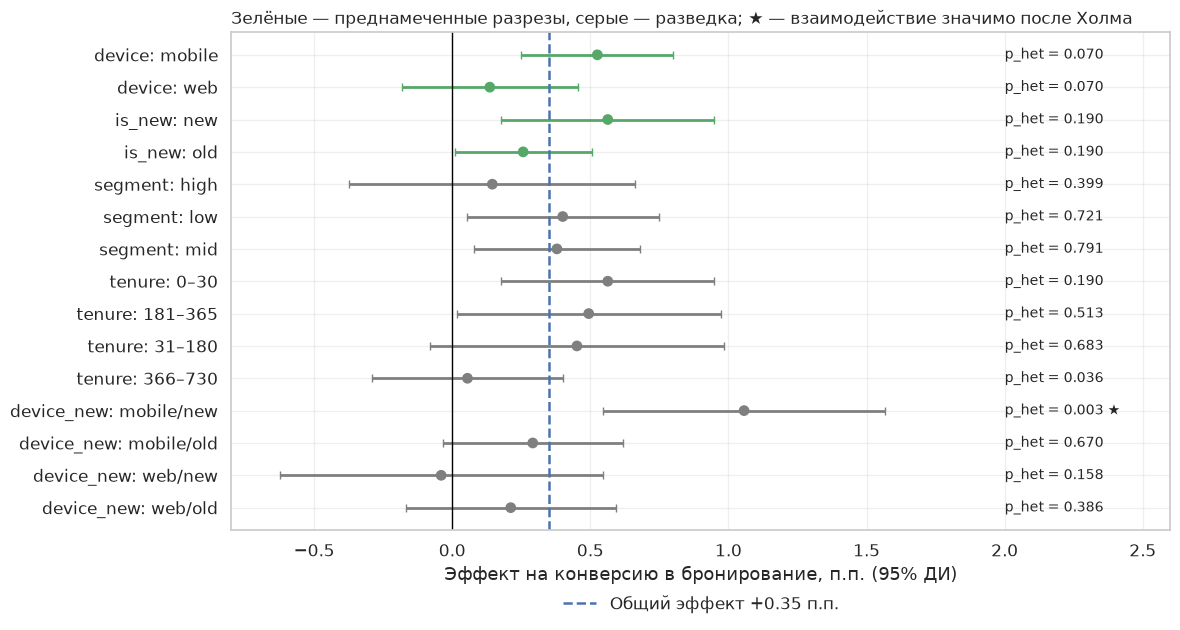

In [18]:
fig, ax = plt.subplots(figsize=(12, 6.5))
order = slices.iloc[::-1].reset_index(drop=True)
colors = [GREEN if s in PREREGISTERED else GRAY for s in order['slice']]
for i, row in order.iterrows():
    ax.errorbar(row['effect_pp'], i, xerr=1.96 * row['se_pp'], fmt='none', ecolor=colors[i], capsize=3, lw=2)
ax.scatter(order['effect_pp'], order.index, c=colors, s=45, zorder=3)
ax.axvline(0, color='black', lw=1)
ax.axvline(100 * total['effect'], color=BLUE, ls='--', lw=1.8, label=f"Общий эффект {100 * total['effect']:+.2f} п.п.")
for i, row in order.iterrows():
    mark = ' ★' if row['p_het_holm'] < 0.05 else ''
    ax.text(2.0, i, f"p_het = {row['p_het']:.3f}{mark}", va='center', fontsize=10)
ax.set_yticks(order.index, [f"{s}: {v}" for s, v in zip(order['slice'], order['value'])])
ax.set_xlim(-0.8, 2.6)
ax.set_xlabel('Эффект на конверсию в бронирование, п.п. (95% ДИ)')
ax.set_title('Зелёные — преднамеченные разрезы, серые — разведка; ★ — взаимодействие значимо после Холма', loc='left', fontsize=12)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), frameon=False)
plt.tight_layout()
plt.show()

**Вопрос.** Продакт пишет: «В 8 сегментах из 15 значимо! Особенно low и mid». Что вы отвечаете и что попадает в отчёт?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

1. **«Значимо против нуля» — не тот вопрос.** Общий эффект +0.35 п.п. значим. Поэтому в любом крупном сегменте эффект тоже «значим»: там тот же средний эффект. Сегмент интересен, только если он **отличается от остальных**. Это тест взаимодействия (`p_het`). У low и mid `p_het` = 0.72 и 0.79 — ничем не отличаются.
2. **Скрытая множественность.** A/A-проверка: при перемешанных метках хотя бы один из 15 сегментов «выстреливает» примерно в трети прогонов. 8 «значимых» без поправки — в основном отражение общего эффекта. После Холма против нуля остаются 2 (mobile и mobile/new).
3. **Преднамеченные разрезы** (device, is_new): точечные оценки различаются — мобильные +0.53 против +0.14 п.п. у веба, новички +0.56 против +0.26 п.п. Но взаимодействие незначимо ($p_{het}$ = 0.07 и 0.19). Тест не рассчитывали на сегменты, а SE разницы вдвое больше SE общего эффекта. В отчёт: «направление согласуется с гипотезой, мощности не хватило».
4. **Разведка.** Единственный разрез, переживший Холма по взаимодействию, — mobile/new: +1.06 п.п. против +0.21 у остальных, $p_{het}$ = 0.003, после Холма — 0.045, на самой границе: при чуть другом числе разрезов он бы не прошёл. Это **гипотеза** для подтверждающего теста на мобильных новичках, а не основание для таргетированной раскатки. Лучший из 15 сегментов к тому же переоценён (проклятие победителя).
5. Замечание о данных: `tenure 0–30` — это ровно `is_new = new`. Одни и те же пользователи под двумя именами — тоже скрытая множественность.
6. Все оценки — средние за 28 дней. В кейсе встречи 4 эффект затухал по когортам, поэтому и средний эффект, и сегментные эффекты завышают долгосрочный. Новизна здесь не учтена (см. встречу 4).

</details>

## Задание 4. Портфель и ревью-борд (13 минут)

Шесть тестов квартала, эффект и SE — в п.п. конверсии. Это тесты другого продукта — маркетплейса с базой конверсии около 5%. CHK-203 — его чекаут, не наш сквозной кейс. Базы конверсии у тестов близки (4.7–5.2%), поэтому эффекты в п.п. сравнимы. При сильно разных базах объединяют относительные эффекты $\hat\theta_i/p_{A,i}$.

1. Напишите `meta_analysis(effect, se)` → словарь `fe`, `se_fe`, `q`, `i2`, `tau2`, `re`, `se_re` (fixed effects с весами $1/SE^2$, $Q$, $I^2$, DerSimonian–Laird $\tau^2$, random effects).
2. Посчитайте `meta_all` по всем тестам. Найдите `outlier` — тест, без которого $I^2$ падает сильнее всего (leave-one-out), и `meta_wo` — мета-анализ без него.
3. Здоровье процесса, две доли: `ship_rate` — доля тестов, прошедших правило встречи 1 (оценка выше `break_even_pp` своего теста); `sig_win_rate` — доля значимых выигрышей ($p < 0.05$, эффект > 0), так считают в отраслевой статистике.
4. *(Необязательно, если осталось время.)* Добавьте в `portfolio` столбец `shrunk`: для пяти тестов без выброса — shrinkage к их среднему random effects с их $\tau^2$: $\tilde\theta_i = \hat\mu_{RE} + \frac{\tau^2}{\tau^2 + SE_i^2}(\hat\theta_i - \hat\mu_{RE})$. Для выброса `shrunk` = сырая оценка: это другой класс изменений, и сжимать его к чужому среднему — то же смешивание, от которого мы только что отказались.

In [19]:
portfolio = pd.read_csv(DATA / 'portfolio_tests.csv')
# Точки безубыточности из планов тестов (условие кейса): у каждого продукта свои затраты и выручка
BE_BY_TEST = {'HD-101': 0.15, 'PRM-104': 0.22, 'CHK-203': 0.25, 'PUSH-307': 0.10, 'ONB-112': 0.40, 'FILT-408': 0.10}
portfolio['break_even_pp'] = portfolio['test_id'].map(BE_BY_TEST)
portfolio[['test_id', 'name', 'n', 'base_rate', 'effect', 'se', 'ci_low', 'ci_high', 'p_value', 'break_even_pp']]

,test_id,name,n,base_rate,effect,se,ci_low,ci_high,p_value,break_even_pp
0,HD-101,Блок рекомендаций на главной,52000,0.050,0.334,0.135,0.069,0.599,0.0135,0.15
1,PRM-104,Промо-баннер в выдаче,38000,0.048,0.276,0.155,-0.028,0.580,0.0751,0.22
2,CHK-203,Новый чекаут v2,78000,0.052,0.187,0.112,-0.033,0.408,0.0954,0.25
3,PUSH-307,Другое время push-рассылки,64000,0.050,0.063,0.122,-0.176,0.302,0.6064,0.10
4,ONB-112,Мобильный онбординг,30000,0.047,1.210,0.173,0.871,1.549,0.0000,0.40
5,FILT-408,Фильтр по цене в поиске,44000,0.051,-0.227,0.148,-0.518,0.064,0.1257,0.10


In [20]:
# ВАШ КОД
raise NotImplementedError

NotImplementedError: 

In [21]:
# @title Решение (нажмите, чтобы раскрыть)
def meta_analysis(effect, se):
    effect, se = np.asarray(effect, float), np.asarray(se, float)
    w = 1 / se ** 2
    fe = np.sum(w * effect) / w.sum()
    q = np.sum(w * (effect - fe) ** 2)
    k = effect.size
    tau2 = max(0.0, (q - (k - 1)) / (w.sum() - np.sum(w ** 2) / w.sum()))
    w_re = 1 / (se ** 2 + tau2)
    return {'fe': fe, 'se_fe': 1 / np.sqrt(w.sum()), 'q': q, 'i2': max(0.0, (q - (k - 1)) / q),
            'tau2': tau2, 're': np.sum(w_re * effect) / w_re.sum(), 'se_re': 1 / np.sqrt(w_re.sum())}


meta_all = meta_analysis(portfolio['effect'], portfolio['se'])
loo = {row.test_id: meta_analysis(portfolio.loc[portfolio.index != i, 'effect'], portfolio.loc[portfolio.index != i, 'se'])['i2']
       for i, row in portfolio.iterrows()}
outlier = min(loo, key=loo.get)
rest = portfolio[portfolio['test_id'] != outlier]
meta_wo = meta_analysis(rest['effect'], rest['se'])

ship_rate = (portfolio['effect'] > portfolio['break_even_pp']).mean()
sig_win_rate = ((portfolio['p_value'] < 0.05) & (portfolio['effect'] > 0)).mean()

# Необязательный пункт: shrinkage к RE пяти сравнимых тестов; выброс не сжимаем
is_outlier = portfolio['test_id'] == outlier
weight = meta_wo['tau2'] / (meta_wo['tau2'] + portfolio['se'] ** 2)
portfolio['shrunk'] = np.where(is_outlier, portfolio['effect'],
                               meta_wo['re'] + weight * (portfolio['effect'] - meta_wo['re']))
ship_shrunk = portfolio['shrunk'] > portfolio['break_even_pp']

for name, m in [('Все 6', meta_all), (f'Без {outlier}', meta_wo)]:
    print(f"{name}: FE {m['fe']:+.3f} ± {1.96 * m['se_fe']:.3f}, RE {m['re']:+.3f} ± {1.96 * m['se_re']:.3f} п.п.; "
          f"Q = {m['q']:.1f} (p = {chi2.sf(m['q'], 5 if name == 'Все 6' else 4):.1e}), I² = {m['i2']:.0%}, τ = {np.sqrt(m['tau2']):.3f}")
print(f"Leave-one-out I²: " + ', '.join(f"{k} {v:.0%}" for k, v in loo.items()))
print(f"Прошли своё правило (оценка > BE): {ship_rate:.0%}; значимых выигрышей: {sig_win_rate:.0%}; по сжатым оценкам выше BE: {ship_shrunk.mean():.0%}")
print(f"Без {outlier}: средний эффект сырой {rest['effect'].mean():+.3f}, после shrinkage {portfolio.loc[~is_outlier, 'shrunk'].mean():+.3f} п.п.; "
      f"{outlier} — отдельно: {portfolio.loc[is_outlier, 'effect'].item():+.2f} п.п.")
portfolio[['test_id', 'effect', 'se', 'p_value', 'break_even_pp', 'shrunk']].round(3)

Все 6: FE +0.245 ± 0.109, RE +0.298 ± 0.329 п.п.; Q = 44.3 (p = 2.1e-08), I² = 89%, τ = 0.386
Без ONB-112: FE +0.134 ± 0.115, RE +0.129 ± 0.180 п.п.; Q = 9.5 (p = 4.9e-02), I² = 58%, τ = 0.156
Leave-one-out I²: HD-101 91%, PRM-104 91%, CHK-203 91%, PUSH-307 90%, ONB-112 58%, FILT-408 88%
Прошли своё правило (оценка > BE): 50%; значимых выигрышей: 33%; по сжатым оценкам выше BE: 33%
Без ONB-112: средний эффект сырой +0.127, после shrinkage +0.129 п.п.; ONB-112 — отдельно: +1.21 п.п.


,test_id,effect,se,p_value,break_even_pp,shrunk
0,HD-101,0.334,0.135,0.014,0.15,0.246
1,PRM-104,0.276,0.155,0.075,0.22,0.203
2,CHK-203,0.187,0.112,0.095,0.25,0.167
3,PUSH-307,0.063,0.122,0.606,0.10,0.088
4,ONB-112,1.210,0.173,0.000,0.40,1.210
5,FILT-408,-0.227,0.148,0.126,0.10,-0.058


**Проверка.**

In [22]:
# Проверка
assert abs(meta_all['fe'] - 0.245) < 0.001 and abs(meta_all['q'] - 44.25) < 0.05
assert abs(meta_all['i2'] - 0.887) < 0.002 and abs(np.sqrt(meta_all['tau2']) - 0.386) < 0.002
assert abs(meta_all['re'] - 0.298) < 0.002 and meta_all['se_re'] > 2.5 * meta_all['se_fe']
assert outlier == 'ONB-112' and abs(meta_wo['i2'] - 0.581) < 0.002 and abs(meta_wo['re'] - 0.129) < 0.002
push = portfolio.set_index('test_id').loc['PUSH-307']
assert abs(push['shrunk'] - 0.088) < 0.002, 'Shrinkage: к RE-среднему пяти тестов, с их τ²'
assert portfolio.loc[portfolio['test_id'] == outlier, 'shrunk'].item() == portfolio.loc[portfolio['test_id'] == outlier, 'effect'].item(), 'Выброс не сжимаем к среднему остальных'
assert abs(ship_rate - 0.5) < 1e-9 and abs(sig_win_rate - 1 / 3) < 1e-9, 'Две доли: по своему BE и по значимости'
print('Задание 4 принято')

Задание 4 принято


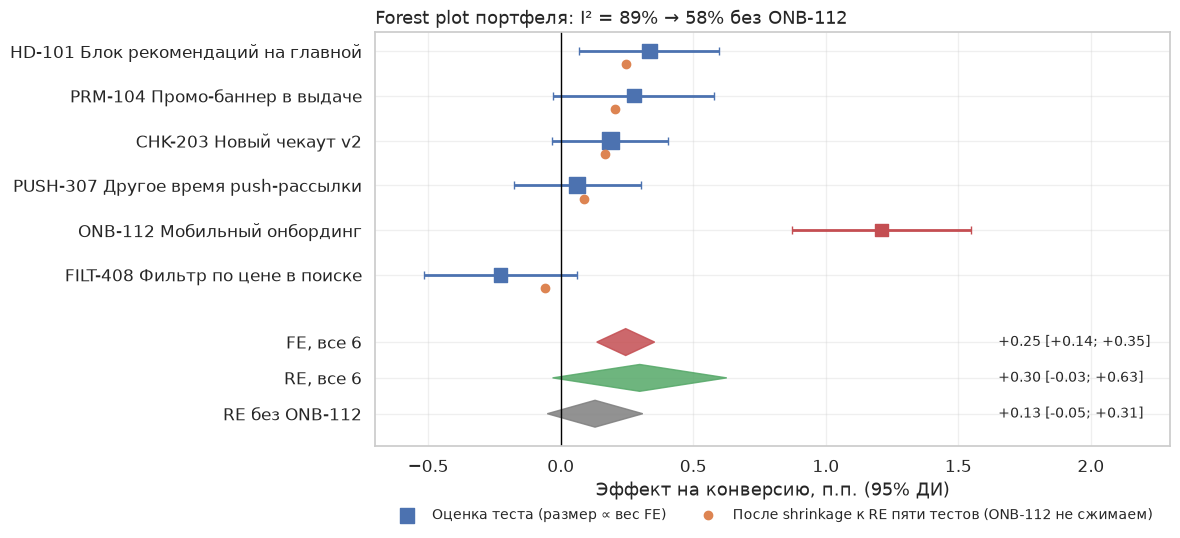

In [23]:
fig, ax = plt.subplots(figsize=(12, 5.6))
rows = np.arange(len(portfolio))[::-1] + 3
heterogeneous = portfolio['test_id'] == outlier
for y, e, s_, h in zip(rows, portfolio['effect'], portfolio['se'], heterogeneous):
    ax.errorbar(e, y, xerr=1.96 * s_, fmt='none', ecolor=RED if h else BLUE, capsize=3, lw=2)
ax.scatter(portfolio['effect'], rows, marker='s', s=30 + 120 * (portfolio['se'].min() / portfolio['se']) ** 2,
           color=[RED if h else BLUE for h in heterogeneous], zorder=3, label='Оценка теста (размер ∝ вес FE)')
ax.scatter(portfolio.loc[~heterogeneous, 'shrunk'], rows[~heterogeneous.to_numpy()] - 0.3, color=ORANGE, zorder=3,
           label='После shrinkage к RE пяти тестов (ONB-112 не сжимаем)')
for y, m, name, color in [(1.5, meta_all, 'FE, все 6', RED), (0.7, meta_all, 'RE, все 6', GREEN), (-0.1, meta_wo, f'RE без {outlier}', GRAY)]:
    centre = m['fe'] if name.startswith('FE') else m['re']
    half = 1.96 * (m['se_fe'] if name.startswith('FE') else m['se_re'])
    ax.fill([centre - half, centre, centre + half, centre], [y, y + 0.3, y, y - 0.3], color=color, alpha=0.85)
    ax.text(1.65, y, f"{centre:+.2f} [{centre - half:+.2f}; {centre + half:+.2f}]", va='center', fontsize=10)
ax.axvline(0, color='black', lw=1)
ax.set_yticks([*rows, 1.5, 0.7, -0.1], [f"{t} {n}" for t, n in zip(portfolio['test_id'], portfolio['name'])] + ['FE, все 6', 'RE, все 6', f'RE без {outlier}'])
ax.set_xlim(-0.7, 2.3)
ax.set_xlabel('Эффект на конверсию, п.п. (95% ДИ)')
ax.set_title(f"Forest plot портфеля: I² = {meta_all['i2']:.0%} → {meta_wo['i2']:.0%} без {outlier}", loc='left')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, fontsize=10)
plt.tight_layout()
plt.show()

**Вопрос.** Что сказать ревью-борду о портфеле: каков «средний эффект теста», какой тест гетерогенный и что значит нулевой PUSH-307?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

* **Все шесть усреднять нельзя.** $Q = 44$ при 5 степенях свободы, $I^2 = 89\%$: почти весь разброс — не шум.
* Fixed effects даёт +0.25 ± 0.11 п.п., но эта точность ложная. Random effects честнее: +0.30 ± 0.33 п.п., ДИ задевает ноль.
* Чего ждать от нового теста — интервал предсказания $\hat\mu_{RE} \pm t_{0.975,\,k-2}\sqrt{\hat\tau^2 + SE_{RE}^2}$: от −0.9 до +1.5 п.п. (t-квантиль, $k-2 = 4$; с z-квантилем было бы −0.5…+1.1).
* **Гетерогенный тест — ONB-112** (мобильный онбординг, +1.21 п.п.). Без него $I^2$ = 58%, среднее RE +0.13 п.п. Это другой класс изменений (новый сценарий, а не правка экрана). Его не выбрасываем и не сжимаем к чужому среднему: в отчёте он идёт отдельной строкой.
* **PUSH-307 — нулевой, и это результат.** Оценка +0.06 п.п., ДИ от −0.18 до +0.30: эффект больше 0.3 п.п. маловероятен. Время рассылки — слабый рычаг. После shrinkage +0.09: шумный тест подтягивается к среднему.
* **FILT-408** (−0.23 п.п., p = 0.13) похож на вред и после shrinkage остаётся отрицательным (−0.06). Не внедряем.
* **Здоровье процесса.** Своё правило (оценка выше BE) прошли 3 из 6: HD-101, PRM-104, ONB-112. Значимых выигрышей 2 из 6, около трети, как в отрасли. Разница ожидаема: при α = 0.5 против BE мы сознательно внедряем больше.
* **Сжатые оценки нужны для победителей.** Среднее пяти тестов shrinkage почти не меняет (+0.127 → +0.129). Зато внедрённые HD-101 и PRM-104 сжимаются в среднем с +0.31 до +0.22 п.п. У PRM-104 сжатая оценка +0.20 уже ниже его BE 0.22: на ожидания квартала её не закладываем. Ожидания следующего квартала — по сжатым оценкам и RE без выброса (+0.13 п.п.), онбординг — отдельно.

</details>

## Задание 5. Мемо на страницу (8 минут)

Шаблон — `memo_template.md`. Заполните словарь `MEMO`: функция `render_memo` ниже соберёт из него мемо по шаблону. Числа берите из переменных заданий 1–2, тексты пишите сами — коротко, для владельца продукта.

Поля: `title` (`<Название> · <даты> · <сплит, n>`), `decision` (одна из строк задания 2), `why` (одна фраза), `effect_rel` (доля), `rule` (строка), `effect_pp`, `ci_pp`, `money_mln`, `money_ci_mln`, `break_even_pp`, `guardrail` (строка), `secondary` (строка), `data_quality` (строка), `risks` (список строк), `segments` (строка), `next_steps` (список строк).

In [24]:
def render_memo(m: dict) -> str:
    """Собирает мемо по структуре memo_template.md."""
    lines = [
        f"## {m['title']}",
        '',
        f"**Решение: {m['decision']}** — {m['why']}",
        '',
        '| | |',
        '| --- | --- |',
        f"| Эффект на OEC (конверсия) | {m['effect_pp']:+.2f} п.п., 95% ДИ [{m['ci_pp'][0]:+.2f}; {m['ci_pp'][1]:+.2f}] (≈ {m['effect_rel']:+.1%} относительных) |",
        f"| В деньгах за 12 мес., чистыми | {m['money_mln']:+.0f} млн ₽, 95% ДИ [{m['money_ci_mln'][0]:+.0f}; {m['money_ci_mln'][1]:+.0f}] |",
        f"| Порог решения | {m['break_even_pp']} п.п. (точка безубыточности) — правило до запуска: {m['rule']} |",
        f"| Guardrail | {m['guardrail']} |",
        f"| Вторичные метрики | {m['secondary']} |",
        f"| Качество данных | {m['data_quality']} |",
        '',
        '**Риски и допущения**',
        *[f"- {r}" for r in m['risks']],
        '',
        f"**Сегменты (только преднамеченные):** {m['segments']}",
        '',
        '**Что дальше**',
        *[f"{i}. {s}" for i, s in enumerate(m['next_steps'], 1)],
    ]
    return '\n'.join(lines)

In [25]:
# ВАШ КОД
raise NotImplementedError

NotImplementedError: 

In [26]:
# @title Решение (нажмите, чтобы раскрыть)
MEMO = {
    'title': (f"Новый чекаут · {df['date'].min()} — {df['date'].max()} · 80/20, "
              f"A = {spaced(counts['A'])}, B = {spaced(counts['B'])}"),
    'decision': DECISION,
    'why': 'конверсия выросла с запасом над порогом, но ошибки оплаты не доказали non-inferiority: чиним и подтверждаем.',
    'effect_rel': effect_pp / (100 * p_a),
    'rule': f"внедряем, если оценка > {BE_PP} п.п. и guardrail доказал non-inferiority (+{NI_MARGIN_PP} п.п.)",
    'effect_pp': effect_pp,
    'ci_pp': ci_pp,
    'money_mln': money_net / 1e6,
    'money_ci_mln': (money_ci[0] / 1e6, money_ci[1] / 1e6),
    'break_even_pp': BE_PP,
    'guardrail': (f"ошибки оплаты {guardrail['effect_pp']:+.3f} п.п. (≈ {guardrail['effect_pp']:+.2f}), "
                  f"верхняя граница {guardrail['upper_pp']:+.2f} п.п. "
                  f"при допустимых +{NI_MARGIN_PP} — **не прошёл**"),
    'secondary': (f"время на чекауте {results.loc['checkout_time_sec', 'effect']:+.1f} с (значимо после Холма); ".replace('-', '−')
                  + f"ARPU {results.loc['revenue', 'effect']:+.0f} ₽, незначимо (p = {results.loc['revenue', 'p_adj']:.2f})"),
    'data_quality': f"удалены дубли и пользователи в обеих группах ({spaced(len(raw) - len(df))} строк); SRM p = {srm_p:.2f}",
    'risks': [
        'Деньги — через конверсию при допущении «средний чек не меняется»; в тесте чек −0.5% (незначимо). По ARPU точечная оценка ≈ +79 млн ₽, ДИ накрывает ноль — нижняя оценка денег реалистичнее верхней.',
        'Ошибки оплаты могут бить по повторным покупкам и нагрузке на поддержку — в 14 днях теста это не видно.',
        'Эффект измерен за 2 недели: эффект новизны не исключён, после раскатки — мониторинг 4 недели.',
        f'Цена ожидания: ≈ 2.7 млн ₽ выручки в неделю (при θ = 2%); фикс + подтверждающий тест ({confirm_weeks} нед.) ≈ {2.7 * (1 + confirm_weeks):.0f} млн ₽, поэтому фикс — приоритет.',
    ],
    'segments': 'в дизайн-доке не заявлялись, поэтому не отчитываемся; разведочные разрезы — только как гипотезы.',
    'next_steps': [
        'Найти и исправить причину роста ошибок оплаты (способ оплаты, платформа, банк) — команда платежей, 1 неделя.',
        (f'Подтверждающий тест 50/50 на {confirm_weeks} недели ({confirm_days} дн. трафика, {spaced(confirm_n)} польз.) '
         f'на мощность guardrail {CONFIRM_POWER} (граница +{NI_MARGIN_PP} п.п.) — по правилу эскалации из дизайн-дока '
         'встречи 2; правило решения записать до запуска — аналитик чекаута, старт сразу после фикса.'),
        'Занести тест в портфель с исходом «OEC выше порога, guardrail не прошёл» — аналитик чекаута, до ревью-борда.',
    ],
}
memo_md = render_memo(MEMO)
display(Markdown(memo_md))

## Новый чекаут · 2026-09-07 — 2026-09-20 · 80/20, A = 83 878, B = 21 082

**Решение: не внедряем как есть** — конверсия выросла с запасом над порогом, но ошибки оплаты не доказали non-inferiority: чиним и подтверждаем.

| | |
| --- | --- |
| Эффект на OEC (конверсия) | +1.40 п.п., 95% ДИ [+0.71; +2.08] (≈ +2.0% относительных) |
| В деньгах за 12 мес., чистыми | +118 млн ₽, 95% ДИ [+48; +187] |
| Порог решения | 0.246 п.п. (точка безубыточности) — правило до запуска: внедряем, если оценка > 0.246 п.п. и guardrail доказал non-inferiority (+0.2 п.п.) |
| Guardrail | ошибки оплаты +0.198 п.п. (≈ +0.20), верхняя граница +0.38 п.п. при допустимых +0.2 — **не прошёл** |
| Вторичные метрики | время на чекауте −3.2 с (значимо после Холма); ARPU +38 ₽, незначимо (p = 0.13) |
| Качество данных | удалены дубли и пользователи в обеих группах (370 строк); SRM p = 0.49 |

**Риски и допущения**
- Деньги — через конверсию при допущении «средний чек не меняется»; в тесте чек −0.5% (незначимо). По ARPU точечная оценка ≈ +79 млн ₽, ДИ накрывает ноль — нижняя оценка денег реалистичнее верхней.
- Ошибки оплаты могут бить по повторным покупкам и нагрузке на поддержку — в 14 днях теста это не видно.
- Эффект измерен за 2 недели: эффект новизны не исключён, после раскатки — мониторинг 4 недели.
- Цена ожидания: ≈ 2.7 млн ₽ выручки в неделю (при θ = 2%); фикс + подтверждающий тест (4 нед.) ≈ 14 млн ₽, поэтому фикс — приоритет.

**Сегменты (только преднамеченные):** в дизайн-доке не заявлялись, поэтому не отчитываемся; разведочные разрезы — только как гипотезы.

**Что дальше**
1. Найти и исправить причину роста ошибок оплаты (способ оплаты, платформа, банк) — команда платежей, 1 неделя.
2. Подтверждающий тест 50/50 на 4 недели (23 дн. трафика, 167 699 польз.) на мощность guardrail 0.9 (граница +0.2 п.п.) — по правилу эскалации из дизайн-дока встречи 2; правило решения записать до запуска — аналитик чекаута, старт сразу после фикса.
3. Занести тест в портфель с исходом «OEC выше порога, guardrail не прошёл» — аналитик чекаута, до ревью-борда.

**Проверка.** Решение — первой строкой после заголовка и совпадает с правилом; числа — из анализа, а не переписаны руками.

In [27]:
# Проверка
memo_md = render_memo(MEMO)
lines = memo_md.splitlines()
assert lines[0].startswith('## ') and lines[2].startswith(f"**Решение: {DECISION}**"), 'Заголовок, затем решение'
assert abs(MEMO['effect_rel'] - effect_pp / (100 * p_a)) < 1e-9
assert MEMO['decision'] == 'не внедряем как есть'
assert abs(MEMO['effect_pp'] - effect_pp) < 1e-9 and np.allclose(MEMO['ci_pp'], ci_pp)
assert abs(MEMO['money_mln'] - money_net / 1e6) < 0.5 and np.allclose(MEMO['money_ci_mln'], np.array(money_ci) / 1e6, atol=0.5)
assert MEMO['break_even_pp'] == BE_PP
assert len(MEMO['risks']) >= 2 and len(MEMO['next_steps']) >= 2, 'Хотя бы два риска и два следующих шага'
assert 'не прош' in MEMO['guardrail'].lower(), 'Guardrail: явно написать, что non-inferiority не доказана'
print('Задание 5 принято')

Задание 5 принято


Пример готового мемо — для сравнения со своим. Это дословный вывод `render_memo` по решению выше.

<details>
<summary><b>Пример мемо</b> (нажмите, чтобы раскрыть)</summary>

## Новый чекаут · 2026-09-07 — 2026-09-20 · 80/20, A = 83 878, B = 21 082

**Решение: не внедряем как есть** — конверсия выросла с запасом над порогом, но ошибки оплаты не доказали non-inferiority: чиним и подтверждаем.

| | |
| --- | --- |
| Эффект на OEC (конверсия) | +1.40 п.п., 95% ДИ [+0.71; +2.08] (≈ +2.0% относительных) |
| В деньгах за 12 мес., чистыми | +118 млн ₽, 95% ДИ [+48; +187] |
| Порог решения | 0.246 п.п. (точка безубыточности) — правило до запуска: внедряем, если оценка > 0.246 п.п. и guardrail доказал non-inferiority (+0.2 п.п.) |
| Guardrail | ошибки оплаты +0.198 п.п. (≈ +0.20), верхняя граница +0.38 п.п. при допустимых +0.2 — **не прошёл** |
| Вторичные метрики | время на чекауте −3.2 с (значимо после Холма); ARPU +38 ₽, незначимо (p = 0.13) |
| Качество данных | удалены дубли и пользователи в обеих группах (370 строк); SRM p = 0.49 |

**Риски и допущения**
- Деньги — через конверсию при допущении «средний чек не меняется»; в тесте чек −0.5% (незначимо). По ARPU точечная оценка ≈ +79 млн ₽, ДИ накрывает ноль — нижняя оценка денег реалистичнее верхней.
- Ошибки оплаты могут бить по повторным покупкам и нагрузке на поддержку — в 14 днях теста это не видно.
- Эффект измерен за 2 недели: эффект новизны не исключён, после раскатки — мониторинг 4 недели.
- Цена ожидания: ≈ 2.7 млн ₽ выручки в неделю (при θ = 2%); фикс + подтверждающий тест (4 нед.) ≈ 14 млн ₽, поэтому фикс — приоритет.

**Сегменты (только преднамеченные):** в дизайн-доке не заявлялись, поэтому не отчитываемся; разведочные разрезы — только как гипотезы.

**Что дальше**
1. Найти и исправить причину роста ошибок оплаты (способ оплаты, платформа, банк) — команда платежей, 1 неделя.
2. Подтверждающий тест 50/50 на 4 недели (23 дн. трафика, 167 699 польз.) на мощность guardrail 0.9 (граница +0.2 п.п.) — по правилу эскалации из дизайн-дока встречи 2; правило решения записать до запуска — аналитик чекаута, старт сразу после фикса.
3. Занести тест в портфель с исходом «OEC выше порога, guardrail не прошёл» — аналитик чекаута, до ревью-борда.

</details>

### Самопроверка по рубрике ревью-борда

Рубрика — в `memo_template.md`: 0 — нет, 1 — частично, 2 — да; готово при сумме ≥ 8 и без нулей. Оценка примера:

| № | Критерий | Балл | Почему |
| :---: | --- | :---: | --- |
| 1 | Решение и правило | 2 | Решение — первой строкой после заголовка; правило записано до запуска и приведено в строке «Порог» |
| 2 | Эффект против порога | 2 | OEC с ДИ в п.п. и в деньгах одной формулой; сравнение с BE 0.246, а не с нулём |
| 3 | Доверие к данным и guardrail | 2 | SRM и очистка указаны; guardrail — non-inferiority с границей +0.2; вторичные — с Холмом и не влияют на решение |
| 4 | Сегменты без p-hacking | 2 | Преднамеченных сегментов нет — так и написано; разведка не выдана за вывод |
| 5 | Риски и следующий шаг | 2 | Допущение о чеке и ARPU-сверка в рисках; у каждого шага владелец и срок; тест идёт в портфель |

Поставьте баллы своему мемо так же.

## Итог

* **Чекаут по лестнице решения.** Данные чистые (SRM p = 0.49) → конверсия +1.40 п.п. [+0.71; +2.08] → +118 млн ₽ [+48; +187] → выше BE 0.246 с запасом → ошибки оплаты: верхняя граница +0.38 > +0.2, не доказано → **не внедряем как есть**. Двусторонний тест против нуля пропустил бы баг.
* **Сегменты.** 8 из 15 «значимы» против нуля, но это эхо общего эффекта. Взаимодействие после Холма — только у mobile/new, это гипотеза для подтверждающего теста. A/A: хотя бы один ложный сегмент — в трети прогонов.
* **Портфель.** $I^2 = 89\%$ из-за ONB-112; без него — 58% и +0.13 п.п. в среднем. Нулевой тест — знание, а не провал. Своё правило прошли 3 из 6, значимо выиграли 2 из 6; сжатые оценки победителей ниже сырых почти на треть: с +0.31 до +0.22 п.п.
* **Артефакт** — мемо по шаблону `memo_template.md` и рубрика ревью-борда.

## Дополнительные задания

### Д1. Переобучение на сегментах

Разделите `hd` пополам по чётности `user_id`. На первой половине найдите разрез с наименьшим `p_het` из 15 (`best_slice`, его `diff_pp` — `found_diff`). Посчитайте тот же разрез на второй половине (`check_diff`, `check_p_het`). Насколько «сдулась» разница?

In [28]:
# ВАШ КОД
raise NotImplementedError

NotImplementedError: 

In [29]:
# @title Решение (нажмите, чтобы раскрыть)
half_1, half_2 = hd[hd['user_id'] % 2 == 0], hd[hd['user_id'] % 2 == 1]
explore = pd.concat([slice_effects(half_1, col) for col in SLICE_COLS], ignore_index=True)
best = explore.loc[explore['p_het'].idxmin()]
best_slice = (best['slice'], best['value'])
found_diff = best['diff_pp']
check = slice_effects(half_2, best['slice']).set_index('value').loc[best['value']]
check_diff, check_p_het = check['diff_pp'], check['p_het']
print(f"Разведка: {best_slice} разница {found_diff:+.2f} п.п., p_het = {best['p_het']:.4f}")
print(f"Проверка: разница {check_diff:+.2f} п.п., p_het = {check_p_het:.3f}")

Разведка: ('device_new', 'mobile/new') разница +0.97 п.п., p_het = 0.0155
Проверка: разница +0.73 п.п., p_het = 0.074


In [30]:
# Проверка
assert best_slice in set(zip(slices['slice'], slices['value']))
assert abs(check_diff) < abs(found_diff), 'На отложенной половине разница должна «сдуться»'
print('Д1 принято')

Д1 принято


<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Лучший разрез на половине данных почти всегда переоценён: его выбрали именно потому, что шум сложился в его пользу. На второй половине разница меньше. Если сегмент реальный (как mobile/new), она остаётся положительной. Если нет — стремится к нулю.

Отложенная половина — дешёвая замена подтверждающего теста. Но она вдвое уменьшает мощность и разведки, и проверки. Поэтому для решения о таргетированной раскатке нужен отдельный тест.

</details>

### Д2. Ratio-метрика: средний чек

Средний чек в B ниже, чем в A. Посчитайте `aov_a`, `aov_b` и SE разницы среднего чека дельта-методом: чек $= \bar R / \bar C$ на пользователя,

$$
\operatorname{Var}\Big(\frac{\bar R}{\bar C}\Big) \approx \frac{1}{n\bar C^2}\Big(\sigma_R^2 - 2\frac{\bar R}{\bar C}\sigma_{RC} + \frac{\bar R^2}{\bar C^2}\sigma_C^2\Big).
$$

Сохраните `aov_diff`, `aov_se`. Значимо ли падение чека? Почему его всё равно нельзя использовать как критерий решения?

In [31]:
# ВАШ КОД
raise NotImplementedError

NotImplementedError: 

In [32]:
# @title Решение (нажмите, чтобы раскрыть)
def ratio_mean_var(r, c):
    r, c = np.asarray(r, float), np.asarray(c, float)
    ratio = r.mean() / c.mean()
    cov = np.cov(r, c, ddof=1)
    var = (cov[0, 0] - 2 * ratio * cov[0, 1] + ratio ** 2 * cov[1, 1]) / (r.size * c.mean() ** 2)
    return ratio, var


aov_a, var_a = ratio_mean_var(A['revenue'], A['converted'])
aov_b, var_b = ratio_mean_var(B['revenue'], B['converted'])
aov_diff, aov_se = aov_b - aov_a, np.sqrt(var_a + var_b)
print(f"Средний чек: A = {aov_a:,.0f} ₽, B = {aov_b:,.0f} ₽; разница {aov_diff:+.0f} ₽ ± {1.96 * aov_se:.0f} (p = {2 * norm.sf(abs(aov_diff / aov_se)):.2f})")

Средний чек: A = 3,728 ₽, B = 3,708 ₽; разница -20 ₽ ± 60 (p = 0.52)


In [33]:
# Проверка
assert abs(aov_a - A.loc[A['converted'] == 1, 'revenue'].mean()) < 1e-6
assert aov_diff < 0 and abs(aov_diff / aov_se) < 1.96
print('Д2 принято')

Д2 принято


<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Падение чека на ≈20 ₽ незначимо. Но даже значимое падение не было бы аргументом против внедрения. Знаменатель — покупатели — меняется от самого варианта: новый чекаут доводит до заказа тех, кто раньше бросал корзину, и у них чек чуть ниже. Покупатели A и B — уже не рандомизированные группы.

Решение принимаем по метрике на пользователя (конверсия, ARPU), а чек — диагностика механизма: «рост за счёт числа заказов, а не их размера».

</details>

## Как было на самом деле (истина из генераторов `data/generate_*.py`)

Раскрываем только сейчас, после всех решений.

* **Чекаут:** конверсия 70.0% → 71.1% (+1.1 п.п.; наша оценка +1.40 в пределах ДИ), ошибки оплаты 2.00% → 2.25% (+0.25 п.п. — **хуже** границы non-inferiority). Средний чек и ARPU на заказ не менялись, время на чекауте −2%. Решение «не внедряем как есть» было верным.
* **Горящие предложения:** настоящая гетерогенность — по `device` (мобильным эффект ×2.0, вебу ×0.6) и по новизне (новичкам ×2.4, остальным ×0.68). Значит, mobile/new — реальный сегмент. Сегмент активности (`segment`) **пустой**: множитель 1.0 у low, mid и high. Его «значимость» — эхо общего эффекта и доли новичков в low. Эффект затухает: на когорте первого дня +1.0 п.п., долгосрочный +0.2 п.п. (полупериод около 3 дней). Средние +0.35 п.п. за 28 дней — смесь новизны и долгосрочного эффекта.
* **Портфель:** истинные эффекты 0.32, 0.28, 0.19, 0.06, **1.20** (ONB-112) и −0.22 п.п. Нулевой — PUSH-307, гетерогенный — ONB-112, вредный — FILT-408.